# Autoregressive Text Generation on *Pride and Prejudice*
### Simple RNN vs Bidirectional RNN vs LSTM vs GRU — Foundations of Generative AI (ICT4403), Assignment 2

**Objective.** Build a word-level autoregressive language model that predicts the next word from the previous words, train four recurrent architectures (Simple RNN, Bidirectional RNN, LSTM, GRU) under identical experimental conditions, compare them quantitatively (loss, perplexity, accuracy, training time) and qualitatively (coherence, diversity, contextual consistency, repetition), and study the effect of the sampling temperature on generated text.

**Dataset.** *Pride and Prejudice* by Jane Austen (1813), Project Gutenberg eBook #1342 — https://www.gutenberg.org/ebooks/1342 (public domain).

**Notebook outline**
1. Setup and configuration
2. Dataset loading and description
3. Preprocessing and tokenisation
4. Building input–target sequences
5. Model definitions
6. Training (identical conditions for all four models)
7. Quantitative evaluation (loss, perplexity, top-1 / top-5 accuracy, training time)
8. Text generation from fixed seeds at several temperatures
9. Generation metrics (diversity, repetition, coherence proxies) and temperature analysis
10. Saving results

## 1. Setup and configuration

In [1]:
# Run this once on Colab / a fresh environment if anything is missing:
# !pip install -q tensorflow numpy pandas matplotlib

import os, re, json, time, random, platform, collections, urllib.request
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow info logs
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("Python:", platform.python_version())
gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", bool(gpus), gpus)

I0000 00:00:1792155599.073416     780 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792155600.622324     780 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0 | Keras: 3.15.1
Python: 3.13.16
GPU available: False []


In [2]:
# ---------------- Experiment configuration (shared by ALL models) ----------------
SEED          = 42
SEQ_LEN       = 20      # number of previous words used to predict the next word
MIN_FREQ      = 2       # words seen fewer times become <unk>
EMBED_DIM     = 100
RNN_UNITS     = 256     # hidden units in the recurrent layer (per direction for the BiRNN)
DROPOUT       = 0.2
BATCH_SIZE    = 256
MAX_EPOCHS    = 25
PATIENCE      = 3       # early stopping on validation loss
LEARNING_RATE = 1e-3
CLIP_NORM     = 1.0     # gradient clipping, protects the Simple RNN from exploding gradients
SPLIT         = (0.8, 0.1, 0.1)   # train / validation / test, split by position in the book

TEMPERATURES  = [0.5, 1.0, 1.5]   # required >= 3 sampling temperatures (+ greedy as a reference)
GEN_WORDS     = 50                # words generated per sample
SAMPLES_PER_SEED = 3              # stochastic samples per (model, seed, temperature)
SEEDS = [
    "it is a truth universally acknowledged that",
    "elizabeth could not help thinking that",
    "mr darcy walked towards her and",
]

DATA_DIR, RESULTS_DIR, PLOTS_DIR, MODELS_DIR = "data", "results", "results/plots", "models"
for d in (DATA_DIR, RESULTS_DIR, PLOTS_DIR, MODELS_DIR):
    os.makedirs(d, exist_ok=True)

keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow

## 2. Dataset loading and description
The text is loaded from `data/pride_and_prejudice.txt` if present; otherwise it is downloaded from Project Gutenberg's official GitHub mirror (GITenberg) or, as a fallback, from gutenberg.org directly. Both are eBook #1342.

In [3]:
DATA_PATH = os.path.join(DATA_DIR, "pride_and_prejudice.txt")
SOURCES = [
    "https://raw.githubusercontent.com/GITenberg/Pride-and-Prejudice_1342/master/1342-0.txt",
    "https://www.gutenberg.org/cache/epub/1342/pg1342.txt",
]
if not os.path.exists(DATA_PATH):
    for url in SOURCES:
        try:
            urllib.request.urlretrieve(url, DATA_PATH)
            print("Downloaded from", url)
            break
        except Exception as err:
            print("Could not download from", url, "->", err)

with open(DATA_PATH, encoding="utf-8-sig") as f:
    raw_text = f.read().replace("\r\n", "\n")
print(f"Raw file: {len(raw_text):,} characters")
print(raw_text[:600])

Raw file: 704,189 characters
The Project Gutenberg EBook of Pride and Prejudice, by Jane Austen

This eBook is for the use of anyone anywhere at no cost and with
almost no restrictions whatsoever.  You may copy it, give it away or
re-use it under the terms of the Project Gutenberg License included
with this eBook or online at www.gutenberg.org


Title: Pride and Prejudice

Author: Jane Austen

Posting Date: August 26, 2008 [EBook #1342]
Release Date: June, 1998
Last Updated: March 10, 2018

Language: English

Character set encoding: UTF-8

*** START OF THIS PROJECT GUTENBERG EBOOK PRIDE AND PREJUDICE ***




Produced by A


In [4]:
# Keep only the novel itself: drop the Project Gutenberg header, licence and footer.
start = raw_text.find("It is a truth universally acknowledged")
end_marker = raw_text.find("*** END OF")
book = raw_text[start:end_marker if end_marker != -1 else None]

chapters = re.findall(r"(?im)^\s*chapter\s+[0-9ivxlc]+\.?\s*$", raw_text[start:])
paragraphs = [p for p in re.split(r"\n\s*\n", book) if p.strip()]
sentences = [s for s in re.split(r"(?<=[.!?])\s+", book) if s.strip()]
raw_words = re.findall(r"[A-Za-z']+", book)

stats = {
    "characters": len(book),
    "chapters": len(chapters) + 1,   # chapter 1's heading sits before the cut point
    "paragraphs": len(paragraphs),
    "sentences (approx.)": len(sentences),
    "words": len(raw_words),
    "unique words (case-insensitive)": len(set(w.lower() for w in raw_words)),
    "mean sentence length (words)": round(len(raw_words) / len(sentences), 1),
}
pd.Series(stats, name="value").to_frame()

,value
characters,684810.0
chapters,61.0
paragraphs,2124.0
sentences (approx.),5775.0
words,122165.0
unique words (case-insensitive),6380.0
mean sentence length (words),21.2


**Characteristics of the dataset**
- A single 19th-century English novel (~122k words, 61 chapters), written in a formal, ironic narrative voice with a large share of dialogue.
- Long, clause-heavy sentences with heavy punctuation (commas and semicolons), which makes long-range dependencies important — a good test for gated vs. ungated RNNs.
- A small, recurring cast (Elizabeth, Darcy, Jane, Bingley, Mr and Mrs Bennet, Wickham, …) and a narrow social vocabulary (marriage, fortune, family, visits, letters).
- Typical Zipfian word distribution: a few function words dominate, and a long tail of words appears only once (see the plot below).

## 3. Preprocessing and tokenisation

In [5]:
def clean_text(text):
    text = re.sub(r"\[Illustration.*?\]", " ", text, flags=re.S)             # illustration tags (some editions)
    text = re.sub(r"(?im)^\s*chapter\s+[0-9ivxlc]+\.?\s*$", " ", text)        # chapter headings
    text = text.replace("_", "")                                              # _italics_ markers
    text = text.replace("’", "'").replace("‘", "'").replace("“", " ").replace("”", " ").replace('"', " ")
    text = text.lower()
    text = re.sub(r"\b(mr|mrs|dr|st)\.", r"\1", text)                         # 'mr.' must not end a sentence
    text = text.replace("--", " , ").replace("—", " , ")                      # dashes behave like pauses
    return text

TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?|[.,!?;]")
def tokenize(text):
    return TOKEN_RE.findall(text)

clean = clean_text(book)
tokens = tokenize(clean)
print(f"{len(tokens):,} tokens")
print(" ".join(tokens[:60]))

139,158 tokens
it is a truth universally acknowledged , that a single man in possession of a good fortune , must be in want of a wife . however little known the feelings or views of such a man may be on his first entering a neighbourhood , this truth is so well fixed in the minds of the surrounding families ,


**Preprocessing choices**
- Lower-casing and removal of quotation marks, underscores (italics), chapter headings and the Gutenberg licence.
- Sentence punctuation `. , ! ? ;` is **kept as separate tokens**, so the models learn where sentences and clauses end and the generated text stays readable.
- Contractions and possessives stay whole (`elizabeth's`, `don't`); titles such as `mr.` lose their full stop so they are not mistaken for sentence ends.
- Words occurring fewer than `MIN_FREQ` times are mapped to `<unk>`; index 0 is reserved for `<pad>`. `<unk>` is never sampled during generation.

In [6]:
counts = collections.Counter(tokens)
vocab = ["<pad>", "<unk>"] + [w for w, c in counts.most_common() if c >= MIN_FREQ]
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = np.array(vocab)
PAD, UNK = 0, 1
VOCAB_SIZE = len(vocab)

ids = np.array([word2idx.get(t, UNK) for t in tokens], dtype=np.int32)
unk_rate = float(np.mean(ids == UNK))
print(f"Vocabulary size: {VOCAB_SIZE:,} (words with freq >= {MIN_FREQ}, + <pad>, <unk>)")
print(f"Distinct tokens before thresholding: {len(counts):,}; singletons: {sum(c == 1 for c in counts.values()):,}")
print(f"Share of tokens mapped to <unk>: {unk_rate:.2%}")

dataset_stats = dict(stats, tokens=len(tokens), vocabulary_size=VOCAB_SIZE, unk_rate=round(unk_rate, 4))

Vocabulary size: 3,950 (words with freq >= 2, + <pad>, <unk>)
Distinct tokens before thresholding: 6,352; singletons: 2,404
Share of tokens mapped to <unk>: 1.73%


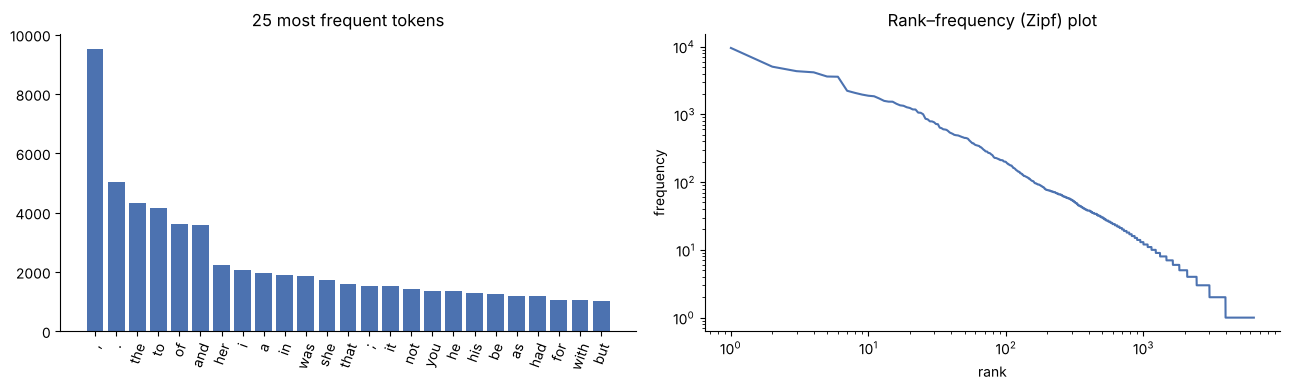

{'elizabeth': 597, 'darcy': 374, 'jane': 264, 'bingley': 257, 'bennet': 294, 'wickham': 162, 'collins': 156, 'lydia': 133}


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
top = counts.most_common(25)
axes[0].bar([w for w, _ in top], [c for _, c in top], color="#4C72B0")
axes[0].set_title("25 most frequent tokens")
axes[0].tick_params(axis="x", rotation=70)
freqs = np.array(sorted(counts.values(), reverse=True))
axes[1].loglog(np.arange(1, len(freqs) + 1), freqs, color="#4C72B0")
axes[1].set_title("Rank–frequency (Zipf) plot"); axes[1].set_xlabel("rank"); axes[1].set_ylabel("frequency")
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{PLOTS_DIR}/dataset_word_frequency.png", dpi=150); plt.show()

names = ["elizabeth", "darcy", "jane", "bingley", "bennet", "wickham", "collins", "lydia"]
print({n: counts[n] for n in names})

## 4. Building input–target sequences for autoregressive modelling
A sliding window of `SEQ_LEN` consecutive tokens is the input, and the token that immediately follows it is the target:

`[w(t-20), …, w(t-1)]  →  w(t)`

To avoid leakage between overlapping windows, the **token stream is split by position first** (first 80% of the book for training, next 10% for validation, last 10% for testing), and windows are built inside each part.

In [8]:
def make_windows(arr, seq_len=SEQ_LEN):
    X = np.lib.stride_tricks.sliding_window_view(arr[:-1], seq_len).astype(np.int32)
    y = arr[seq_len:].astype(np.int32)
    return X, y

n = len(ids)
a, b = int(SPLIT[0] * n), int((SPLIT[0] + SPLIT[1]) * n)
X_train, y_train = make_windows(ids[:a])
X_val,   y_val   = make_windows(ids[a:b])
X_test,  y_test  = make_windows(ids[b:])
print(f"train {X_train.shape}  val {X_val.shape}  test {X_test.shape}")

for i in [0, 1, 2]:
    print(" ".join(idx2word[X_train[i]]), " -->", idx2word[y_train[i]])

dataset_stats.update(train_sequences=len(X_train), val_sequences=len(X_val), test_sequences=len(X_test), seq_len=SEQ_LEN)

train (111306, 20)  val (13896, 20)  test (13896, 20)
it is a truth universally acknowledged , that a single man in possession of a good fortune , must be  --> in
is a truth universally acknowledged , that a single man in possession of a good fortune , must be in  --> want
a truth universally acknowledged , that a single man in possession of a good fortune , must be in want  --> of


## 5. Model definitions
All four models share **the same skeleton** so that only the recurrent layer differs:

`Embedding(V, 100) → recurrent layer (256 units) → Dropout(0.2) → Dense(V, softmax)`

| Model | Recurrent layer | Idea |
|---|---|---|
| Simple RNN | `SimpleRNN(256)` | Plain tanh recurrence; cheapest, but suffers from vanishing gradients over long contexts. |
| Bidirectional RNN | `Bidirectional(SimpleRNN(256))` | Reads the 20-word context forwards and backwards and concatenates both final states (512-d). |
| LSTM | `LSTM(256)` | Input/forget/output gates plus a cell state; designed to keep information over long spans. |
| GRU | `GRU(256)` | Update and reset gates; LSTM-like memory with fewer parameters. |

**Note on the Bidirectional RNN.** Both directions only read the *input window*, which contains past words; the target word is outside the window, so there is no information leakage from the future. The limitation is practical: a bidirectional model cannot update its state incrementally, so the whole window must be re-read from scratch at every generation step, which is less natural for left-to-right autoregressive generation.

The input shape is `(None,)`, so the models also accept seeds shorter than 20 words. Dropout is applied after the recurrent layer (not as recurrent dropout) so that LSTM/GRU can use the fast cuDNN kernels on a GPU.

In [9]:
def build_model(kind):
    rnn = {
        "Simple RNN":        lambda: layers.SimpleRNN(RNN_UNITS),
        "Bidirectional RNN": lambda: layers.Bidirectional(layers.SimpleRNN(RNN_UNITS)),
        "LSTM":              lambda: layers.LSTM(RNN_UNITS),
        "GRU":               lambda: layers.GRU(RNN_UNITS),
    }[kind]()
    model = keras.Sequential([
        keras.Input(shape=(None,), dtype="int32"),
        layers.Embedding(VOCAB_SIZE, EMBED_DIM),
        rnn,
        layers.Dropout(DROPOUT),
        layers.Dense(VOCAB_SIZE, activation="softmax"),
    ], name=kind.replace(" ", "_"))
    model.compile(
        optimizer=keras.optimizers.Adam(LEARNING_RATE, clipnorm=CLIP_NORM),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_accuracy")],
    )
    return model

MODEL_NAMES = ["Simple RNN", "Bidirectional RNN", "LSTM", "GRU"]
COLORS = {"Simple RNN": "#4C72B0", "Bidirectional RNN": "#DD8452", "LSTM": "#55A868", "GRU": "#C44E52"}
for name in MODEL_NAMES:
    m = build_model(name)
    print(f"{name:18s} parameters: {m.count_params():,}")
build_model("LSTM").summary()

Simple RNN         parameters: 1,501,542


Bidirectional RNN  parameters: 2,604,134
LSTM               parameters: 1,775,718


GRU                parameters: 1,685,094


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, None, 100)      │       395,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 256)            │       365,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3950)           │     1,015,150 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,775,718 (6.77 MB)

 Trainable params: 1,775,718 (6.77 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Training under identical conditions
Every model uses the same data split, seed, batch size, optimiser, learning rate, gradient clipping, epoch cap and early-stopping rule (stop when validation loss has not improved for 3 epochs, then restore the best weights). Wall-clock time per epoch is recorded.

In [10]:
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self._t = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self._t)

models, histories, train_info = {}, {}, {}
for name in MODEL_NAMES:
    print(f"\n========== Training {name} ==========")
    keras.utils.set_random_seed(SEED)           # same initialisation seed and shuffling for every model
    model = build_model(name)
    timer = EpochTimer()
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    t0 = time.time()
    hist = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, shuffle=True,
                     callbacks=[timer, stop], verbose=2)
    total = time.time() - t0
    models[name], histories[name] = model, hist.history
    best_epoch = int(np.argmin(hist.history["val_loss"])) + 1
    train_info[name] = dict(total_time_s=total, epochs_run=len(timer.times), best_epoch=best_epoch,
                            sec_per_epoch=float(np.mean(timer.times)), params=model.count_params())
    model.save(f"{MODELS_DIR}/{name.replace(' ', '_').lower()}.keras")
    print(f"{name}: {len(timer.times)} epochs, best epoch {best_epoch}, {total:.0f}s total")


========== Training Simple RNN ==========


Epoch 1/25


435/435 - 25s - 57ms/step - accuracy: 0.0672 - loss: 6.1663 - top5_accuracy: 0.1879 - val_accuracy: 0.0850 - val_loss: 5.7920 - val_top5_accuracy: 0.2137


Epoch 2/25


435/435 - 22s - 50ms/step - accuracy: 0.0962 - loss: 5.6221 - top5_accuracy: 0.2511 - val_accuracy: 0.1033 - val_loss: 5.4067 - val_top5_accuracy: 0.2758


...

Epoch 9/25


435/435 - 84s - 194ms/step - accuracy: 0.2326 - loss: 3.7532 - top5_accuracy: 0.4805 - val_accuracy: 0.1837 - val_loss: 4.6110 - val_top5_accuracy: 0.4041


Epoch 10/25


435/435 - 80s - 184ms/step - accuracy: 0.2466 - loss: 3.6184 - top5_accuracy: 0.5002 - val_accuracy: 0.1849 - val_loss: 4.6414 - val_top5_accuracy: 0.4049


GRU: 10 epochs, best epoch 7, 727s total


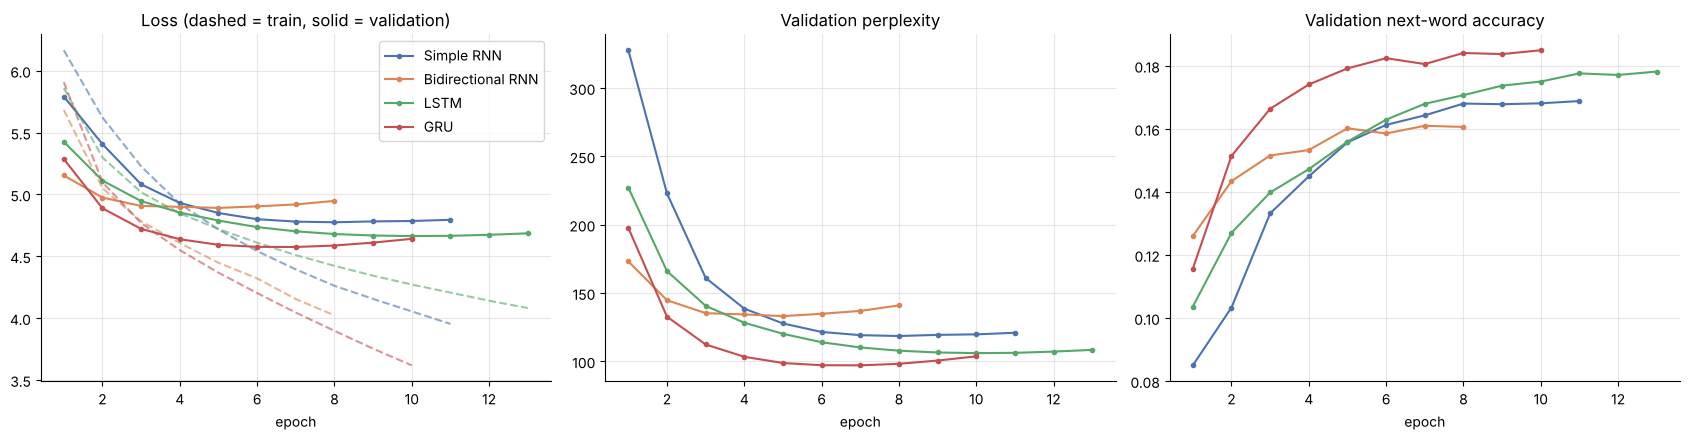

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for name in MODEL_NAMES:
    h, c = histories[name], COLORS[name]
    ep = np.arange(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["loss"], "--", color=c, alpha=0.6)
    axes[0].plot(ep, h["val_loss"], "-o", color=c, ms=3, label=name)
    axes[1].plot(ep, np.exp(h["val_loss"]), "-o", color=c, ms=3, label=name)
    axes[2].plot(ep, h["val_accuracy"], "-o", color=c, ms=3, label=name)
axes[0].set_title("Loss (dashed = train, solid = validation)")
axes[1].set_title("Validation perplexity")
axes[2].set_title("Validation next-word accuracy")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
axes[0].legend()
plt.tight_layout(); plt.savefig(f"{PLOTS_DIR}/training_curves.png", dpi=150); plt.show()

## 7. Quantitative evaluation on the held-out test set
- **Loss**: mean cross-entropy of the true next word.
- **Perplexity** = exp(loss): the effective number of words the model is "choosing between"; lower is better.
- **Top-1 / Top-5 accuracy**: how often the true next word is the model's first choice / among its five most likely words.
- **Training time** and **generation speed** (milliseconds per generated word).

In [12]:
rows = []
for name in MODEL_NAMES:
    loss, acc, top5 = models[name].evaluate(X_test, y_test, batch_size=1024, verbose=0)
    info = train_info[name]
    rows.append({
        "Model": name, "Parameters": info["params"],
        "Test loss": loss, "Test perplexity": float(np.exp(loss)),
        "Top-1 accuracy": acc, "Top-5 accuracy": top5,
        "Best val loss": float(np.min(histories[name]["val_loss"])),
        "Epochs run": info["epochs_run"], "Best epoch": info["best_epoch"],
        "Sec / epoch": info["sec_per_epoch"], "Total train time (s)": info["total_time_s"],
    })
metrics_df = pd.DataFrame(rows).set_index("Model")
metrics_df.round(3)

,Parameters,Test loss,Test perplexity,Top-1 accuracy,Top-5 accuracy,Best val loss,Epochs run,Best epoch,Sec / epoch,Total train time (s)
Model,,,,,,,,,,
Simple RNN,1501542,4.884,132.119,0.162,0.375,4.775,11,8,26.762,310.888
Bidirectional RNN,2604134,4.998,148.182,0.156,0.358,4.891,8,5,39.765,318.234
LSTM,1775718,4.779,119.033,0.175,0.391,4.664,13,10,64.209,860.272
GRU,1685094,4.670,106.700,0.182,0.405,4.576,10,7,72.642,726.550


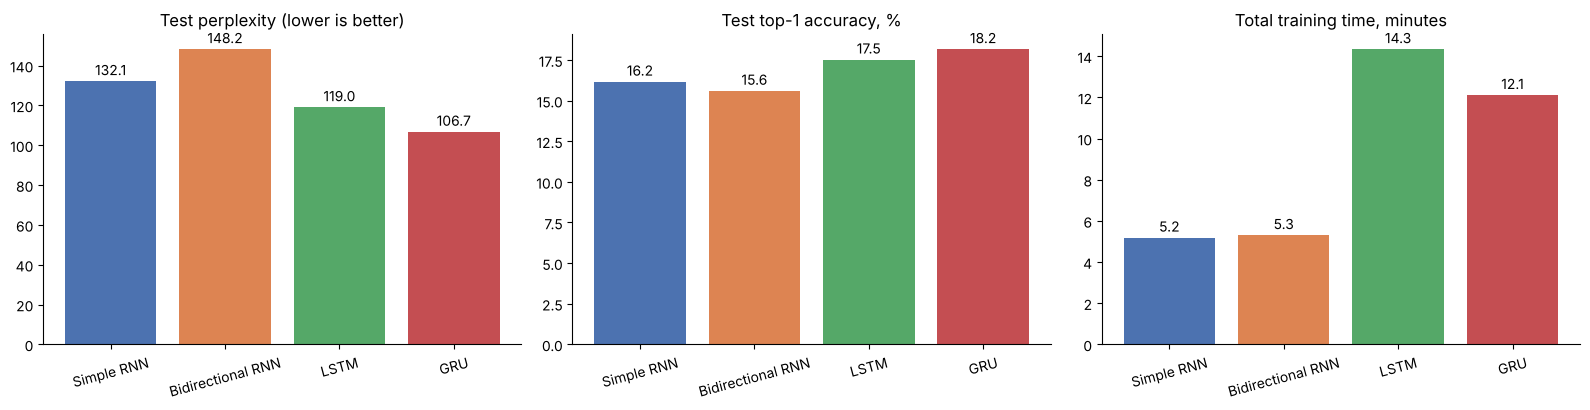

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
cols = [COLORS[m] for m in MODEL_NAMES]
def bar(ax, values, title, fmt):
    bars = ax.bar(MODEL_NAMES, values, color=cols)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], padding=2)
    ax.set_title(title); ax.tick_params(axis="x", rotation=15); ax.spines[["top", "right"]].set_visible(False)
bar(axes[0], metrics_df["Test perplexity"], "Test perplexity (lower is better)", "{:.1f}")
bar(axes[1], metrics_df["Top-1 accuracy"] * 100, "Test top-1 accuracy, %", "{:.1f}")
bar(axes[2], metrics_df["Total train time (s)"] / 60, "Total training time, minutes", "{:.1f}")
plt.tight_layout(); plt.savefig(f"{PLOTS_DIR}/test_metrics_comparison.png", dpi=150); plt.show()

## 8. Autoregressive text generation
At each step the last `SEQ_LEN` words (or the whole seed while it is shorter) are fed to the model, the next word is drawn from the predicted distribution, appended, and the window slides forward.

**Temperature sampling.** Probabilities are re-scaled as $p_i^{(T)} \propto \exp(\log p_i / T)$:
- $T<1$ sharpens the distribution (safer, more repetitive),
- $T=1$ samples from the model as learnt,
- $T>1$ flattens it (more diverse, more errors).

Greedy decoding (always taking the most likely word, the limit $T \to 0$) is included as a reference. Every model receives the **same three seeds** and the same random-number seed.

In [14]:
def encode(text):
    return [word2idx.get(t, UNK) for t in tokenize(clean_text(text))]

def detokenize(words):
    text = " ".join(words)
    text = re.sub(r" ([.,!?;])", r"\1", text)
    text = re.sub(r"(^|[.!?] )([a-z])", lambda m: m.group(1) + m.group(2).upper(), text)
    text = re.sub(r"\bi\b", "I", text)
    for t in ["mr", "mrs", "elizabeth", "darcy", "jane", "bingley", "bennet", "wickham", "collins",
              "lydia", "kitty", "mary", "charlotte", "lucas", "longbourn", "netherfield", "pemberley",
              "meryton", "london", "catherine", "gardiner", "phillips", "fitzwilliam", "georgiana", "lizzy", "hunsford", "rosings", "lady", "miss", "sir", "colonel", "derbyshire", "brighton", "kent", "hertfordshire", "william", "de", "bourgh"]:
        text = re.sub(rf"\b{t}\b", t.capitalize(), text)
    return text

def continuation(seed_text, gen_tokens):
    # detokenise seed + generated words together, return (seed part, generated part)
    seed_tokens = tokenize(clean_text(seed_text))
    seed_str = detokenize(seed_tokens)
    full = detokenize(seed_tokens + list(gen_tokens))
    return seed_str, full[len(seed_str):]

def generate(model, seed_text, n_words=GEN_WORDS, temperature=1.0, rng=None):
    rng = rng or np.random.default_rng(SEED)
    seq = encode(seed_text)
    generated = []
    for _ in range(n_words):
        x = np.array([seq[-SEQ_LEN:]], dtype=np.int32)
        p = model(x, training=False).numpy()[0].astype(np.float64)
        p[PAD] = p[UNK] = 0.0                             # never emit padding or <unk>
        if temperature == 0:                               # greedy decoding
            nxt = int(np.argmax(p))
        else:
            logits = np.log(p + 1e-12) / temperature
            q = np.exp(logits - logits.max()); q /= q.sum()
            nxt = int(rng.choice(len(q), p=q))
        seq.append(nxt); generated.append(idx2word[nxt])
    return generated

# Quick look: one sample per model for the first seed at T = 1.0
for name in MODEL_NAMES:
    out = generate(models[name], SEEDS[0], 35, 1.0)
    seed_part, gen_part = continuation(SEEDS[0], out)
    print(f"[{name}] {seed_part} >>{gen_part}\n")

[Simple RNN] It is a truth universally acknowledged that >> may do our excuse the impudence of into the case, sometimes whether Miss Bingley. Mr Darcy came into an face qualities should meet. With the whole importance that desired that you more



[Bidirectional RNN] It is a truth universally acknowledged that >> what my enjoyment your own petticoat your disadvantage to or your offenses of relations to Mr Collins, Charlotte found such his grove tour; and with the Gardiner was employed openly for her morning



[LSTM] It is a truth universally acknowledged that >> Jane is already passed. Unless there will not then any effort with these means to wish. We can assure you expose myself if a different of the lively opening just. You must



[GRU] It is a truth universally acknowledged that >> Charlotte did only credit. Continually called about the case, unless Elizabeth wanted a most eligible young men in every doubt fall within one of his own Miss De Bourgh's gloom. As you



In [15]:
GEN_TEMPS = [0.0] + TEMPERATURES          # 0.0 = greedy reference
samples = []                                # every generated text, kept for metrics and the report
gen_time = {}
for name in MODEL_NAMES:
    t0, steps = time.time(), 0
    for temp in GEN_TEMPS:
        rng = np.random.default_rng(SEED)   # identical random stream for every model / temperature
        n_samples = 1 if temp == 0 else SAMPLES_PER_SEED
        for s_i, seed in enumerate(SEEDS):
            for k in range(n_samples):
                out = generate(models[name], seed, GEN_WORDS, temp, rng)
                steps += GEN_WORDS
                samples.append(dict(model=name, temperature=temp, seed_id=s_i, seed=seed, sample=k, tokens=out))
    gen_time[name] = (time.time() - t0) / steps * 1000
    print(f"{name}: {gen_time[name]:.1f} ms per generated word")
metrics_df["ms / generated word"] = pd.Series(gen_time)
print(f"{len(samples)} texts generated")

Simple RNN: 33.5 ms per generated word


Bidirectional RNN: 62.1 ms per generated word


LSTM: 45.5 ms per generated word


GRU: 57.6 ms per generated word
120 texts generated


In [16]:
def show(temp, seed_id=0, sample=0):
    print(f"Seed: \"{SEEDS[seed_id]}\" | T = {'greedy' if temp == 0 else temp}\n" + "-" * 100)
    for s in samples:
        if s["temperature"] == temp and s["seed_id"] == seed_id and s["sample"] == sample:
            seed_part, gen_part = continuation(s["seed"], s["tokens"])
            print(f"[{s['model']}]\n{seed_part} >>{gen_part}\n")

for temp in GEN_TEMPS:
    show(temp, seed_id=0)

Seed: "it is a truth universally acknowledged that" | T = greedy
----------------------------------------------------------------------------------------------------
[Simple RNN]
It is a truth universally acknowledged that >> I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am

[Bidirectional RNN]
It is a truth universally acknowledged that >> the accounted Darcy, and I Collins him not, be, how I am sure, said Elizabeth, and I am sure, and I am not a very agreeable way. I am sure, I am sure, I am sure, I am sure,

[LSTM]
It is a truth universally acknowledged that >> he had been a very different. I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure

[GRU]
It is a truth universally acknowledged that >> I should not have been in the world. I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I

In [17]:
for temp in GEN_TEMPS:
    show(temp, seed_id=1)

Seed: "elizabeth could not help thinking that" | T = greedy
----------------------------------------------------------------------------------------------------
[Simple RNN]
Elizabeth could not help thinking that >> he had been a great deal of the neighbourhood. I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure,

[Bidirectional RNN]
Elizabeth could not help thinking that >> the Phillips's Gardiner she have been the opinion. The Gardiner did the ladies to the room, and she was not to be in a very dependence of the room. She had heard her to the room, and she was not to be in a very dependence

[LSTM]
Elizabeth could not help thinking that >> she had been in the room, and the other of the evening, and the other of the evening, and the other of the evening, and the other of the evening, and the other of the evening, and the other of the evening, and

[GRU]
Elizabeth could not help thinking that >> she had been in the room. She had

In [18]:
for temp in GEN_TEMPS:
    show(temp, seed_id=2)

Seed: "mr darcy walked towards her and" | T = greedy
----------------------------------------------------------------------------------------------------
[Simple RNN]
Mr Darcy walked towards her and >> the officers, and the girls of the writer were to the same day. I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure

[Bidirectional RNN]
Mr Darcy walked towards her and >> the Gardiner did the ladies to be be have been Catherine was at the same time. She was not to be in a very detached, and she was not to be in a manner of the room, and the weather was soon in the room, and

[LSTM]
Mr Darcy walked towards her and >> the family, and the other of the evening, and the other of the evening, and the other of the evening, and the other of the evening, and the other of the evening, and the other of the evening, and the other of the

[GRU]
Mr Darcy walked towards her and >> aunt, and the two gentlemen was not to be a little deal of the room. The two

## 9. Generation metrics and temperature analysis
Human judgement of the samples above is complemented by automatic proxies computed on the generated words only (seed excluded), averaged over all seeds and samples:

| Metric | What it captures |
|---|---|
| **Distinct-1 / Distinct-2** | unique words / unique bigrams ÷ total → **diversity** (higher = more varied) |
| **Repetition rate** | share of word trigrams that repeat an earlier trigram in the same text → **repetition / loops** (lower is better) |
| **Bigram plausibility** | share of generated bigrams that occur somewhere in the training text → **local coherence / grammaticality** (higher = more fluent) |
| **Novel 4-grams** | share of generated 4-grams that do not occur in the training text → **originality vs. copying** |
| **Seed perplexity** | perplexity of the generated words under the *best* (lowest test perplexity) model → **contextual consistency with the seed** as judged by a strong reference model (lower = more consistent) |

In [19]:
train_tokens = [idx2word[i] for i in ids[:a]]
train_bigrams = set(zip(train_tokens, train_tokens[1:]))
train_4grams = set(zip(train_tokens, train_tokens[1:], train_tokens[2:], train_tokens[3:]))

def ngrams(seq, n): return list(zip(*[seq[i:] for i in range(n)]))
def distinct(seq, n):
    g = ngrams(seq, n); return len(set(g)) / max(len(g), 1)
def repetition(seq, n=3):
    g = ngrams(seq, n); return 1 - len(set(g)) / max(len(g), 1)
def bigram_plausibility(seq, seed_last):
    g = ngrams([seed_last] + seq, 2); return np.mean([bg in train_bigrams for bg in g])
def novel_4grams(seq):
    g = ngrams(seq, 4); return np.mean([fg not in train_4grams for fg in g])

best_model_name = metrics_df["Test perplexity"].idxmin()
ref = models[best_model_name]
def reference_perplexity(seed, gen):
    seq = encode(seed) + [word2idx.get(w, UNK) for w in gen]
    k0 = len(encode(seed))
    logps = []
    for j in range(k0, len(seq)):
        x = np.array([seq[max(0, j - SEQ_LEN):j]], dtype=np.int32)
        p = ref(x, training=False).numpy()[0]
        logps.append(np.log(p[seq[j]] + 1e-12))
    return float(np.exp(-np.mean(logps)))

for s in samples:
    t = s["tokens"]
    s.update(distinct_1=distinct(t, 1), distinct_2=distinct(t, 2), repetition=repetition(t),
             bigram_plausibility=bigram_plausibility(t, tokenize(clean_text(s["seed"]))[-1]),
             novel_4grams=novel_4grams(t), ref_perplexity=reference_perplexity(s["seed"], t))

gen_df = pd.DataFrame(samples)
gen_metrics = (gen_df.groupby(["model", "temperature"])
               [["distinct_1", "distinct_2", "repetition", "bigram_plausibility", "novel_4grams", "ref_perplexity"]]
               .mean().reindex(MODEL_NAMES, level=0))
print("Reference model for seed perplexity:", best_model_name)
gen_metrics.round(3)

Reference model for seed perplexity: GRU


distinct_1  distinct_2  repetition  \
model             temperature                                       
Simple RNN        0.0               0.220       0.252       0.743   
                  0.5               0.618       0.862       0.056   
                  1.0               0.807       0.973       0.002   
                  1.5               0.891       0.998       0.000   
Bidirectional RNN 0.0               0.480       0.680       0.250   
                  0.5               0.633       0.887       0.035   
                  1.0               0.829       0.995       0.000   
                  1.5               0.916       1.000       0.000   
LSTM              0.0               0.193       0.224       0.771   
                  0.5               0.616       0.878       0.044   
                  1.0               0.813       0.986       0.000   
                  1.5               0.902       1.000       0.000   
GRU               0.0               0.320       0.408       0.521   
                  0.5               0.642       0.893       0.032   
                  1.0               0.816       0.993       0.000   
                  1.5               0.896       1.000       0.000   

                               bigram_plausibility  novel_4grams  \
model             temperature                                      
Simple RNN        0.0                        0.993         0.553   
                  0.5                        0.940         0.723   
                  1.0                        0.698         0.941   
                  1.5                        0.362         0.998   
Bidirectional RNN 0.0                        0.867         0.645   
                  0.5                        0.844         0.742   
                  1.0                        0.591         0.976   
                  1.5                        0.287         1.000   
LSTM              0.0                        1.000         0.645   
                  0.5                        0.931         0.730   
                  1.0                        0.656         0.960   
                  1.5                        0.387         0.998   
GRU               0.0                        0.987         0.603   
                  0.5                        0.964         0.700   
                  1.0                        0.736         0.948   
                  1.5                        0.382         0.988   

                               ref_perplexity  
model             temperature                  
Simple RNN        0.0                   6.156  
                  0.5                  19.651  
                  1.0                 110.559  
                  1.5                1205.895  
Bidirectional RNN 0.0                  34.571  
                  0.5                  44.393  
                  1.0                 271.052  
                  1.5                2179.210  
LSTM              0.0                  10.563  
                  0.5                  22.425  
                  1.0                 130.161  
                  1.5                 800.104  
GRU               0.0                   8.314  
                  0.5                  12.642  
                  1.0                  70.606  
                  1.5                 674.928

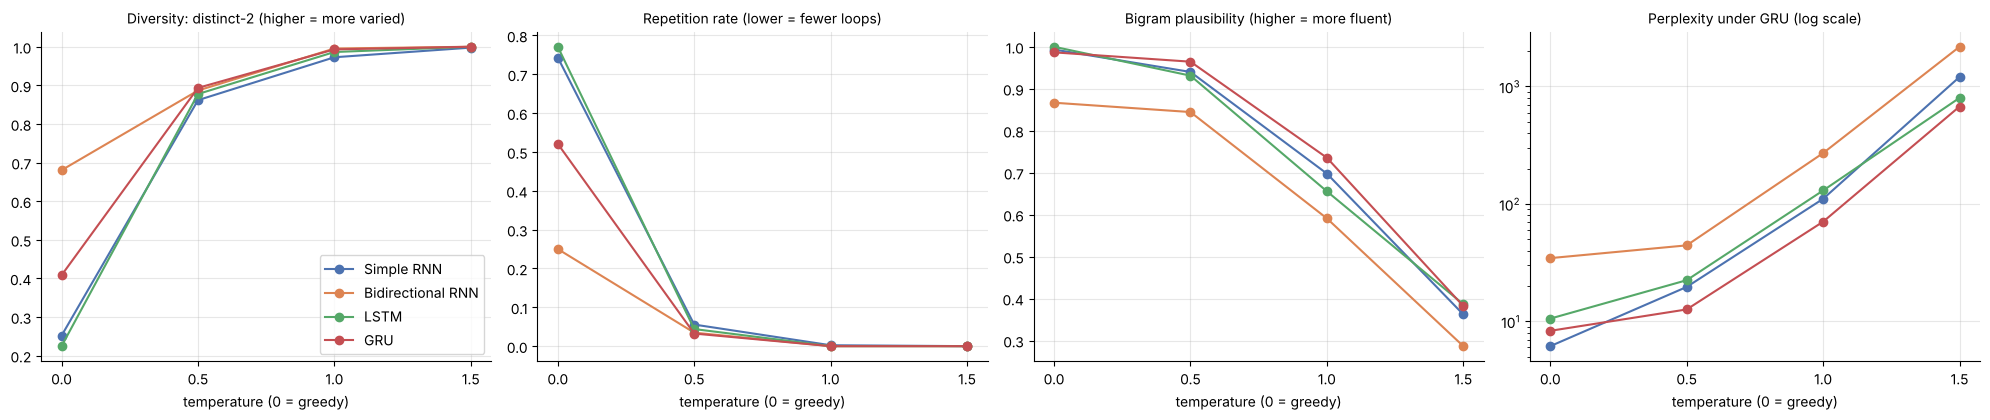

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
panels = [("distinct_2", "Diversity: distinct-2 (higher = more varied)"),
          ("repetition", "Repetition rate (lower = fewer loops)"),
          ("bigram_plausibility", "Bigram plausibility (higher = more fluent)"),
          ("ref_perplexity", f"Perplexity under {best_model_name} (log scale)")]
for ax, (col, title) in zip(axes, panels):
    for name in MODEL_NAMES:
        d = gen_metrics.loc[name]
        ax.plot(d.index, d[col], "-o", color=COLORS[name], label=name)
    ax.set_title(title, fontsize=10); ax.set_xlabel("temperature (0 = greedy)")
    ax.set_xticks(GEN_TEMPS); ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
axes[3].set_yscale("log")
axes[0].legend()
plt.tight_layout(); plt.savefig(f"{PLOTS_DIR}/temperature_effects.png", dpi=150); plt.show()

In [21]:
# One-line summary per model at T = 1.0 (the model's own distribution) next to its test metrics
summary = metrics_df[["Parameters", "Test perplexity", "Top-1 accuracy", "Top-5 accuracy",
                      "Total train time (s)", "ms / generated word"]].copy()
at1 = gen_metrics.xs(1.0, level="temperature")
summary["Distinct-2 @T=1"] = at1["distinct_2"]
summary["Repetition @T=1"] = at1["repetition"]
summary["Bigram plaus. @T=1"] = at1["bigram_plausibility"]
summary.round(3)

,Parameters,Test perplexity,Top-1 accuracy,Top-5 accuracy,Total train time (s),ms / generated word,Distinct-2 @T=1,Repetition @T=1,Bigram plaus. @T=1
Model,,,,,,,,,
Simple RNN,1501542,132.119,0.162,0.375,310.888,33.472,0.973,0.002,0.698
Bidirectional RNN,2604134,148.182,0.156,0.358,318.234,62.078,0.995,0.000,0.591
LSTM,1775718,119.033,0.175,0.391,860.272,45.458,0.986,0.000,0.656
GRU,1685094,106.700,0.182,0.405,726.550,57.564,0.993,0.000,0.736


## 10. Saving results

In [22]:
metrics_df.round(4).to_csv(f"{RESULTS_DIR}/model_metrics.csv")
gen_metrics.round(4).to_csv(f"{RESULTS_DIR}/generation_metrics.csv")
summary.round(4).to_csv(f"{RESULTS_DIR}/summary.csv")
with open(f"{RESULTS_DIR}/training_history.json", "w") as f:
    json.dump({m: {k: [float(v) for v in vals] for k, vals in h.items()} for m, h in histories.items()}, f, indent=1)
with open(f"{RESULTS_DIR}/dataset_stats.json", "w") as f:
    json.dump(dataset_stats, f, indent=1)

with open(f"{RESULTS_DIR}/generated_samples.md", "w") as f:
    f.write("# Generated text samples\n\n")
    f.write(f"Every model, every seed, temperatures {GEN_TEMPS} (0 = greedy). {GEN_WORDS} generated words per sample. "
            "The seed is shown in **bold**.\n\n")
    for s_i, seed in enumerate(SEEDS):
        f.write(f"## Seed {s_i + 1}: \"{seed}\"\n\n")
        for temp in GEN_TEMPS:
            f.write(f"### Temperature {'greedy' if temp == 0 else temp}\n\n")
            for name in MODEL_NAMES:
                for s in samples:
                    if s["model"] == name and s["temperature"] == temp and s["seed_id"] == s_i:
                        seed_part, gen_part = continuation(seed, s["tokens"])
                        f.write(f"- **{name}** (sample {s['sample'] + 1}): **{seed_part}**{gen_part}\n")
            f.write("\n")
with open(f"{RESULTS_DIR}/generated_samples.json", "w") as f:
    json.dump([{k: v for k, v in s.items()} | {"tokens": [str(w) for w in s["tokens"]], "text": "".join(continuation(s["seed"], s["tokens"]))} for s in samples], f, indent=1, default=float)

print(sorted(os.listdir(RESULTS_DIR)), sorted(os.listdir(PLOTS_DIR)))

['dataset_stats.json', 'generated_samples.json', 'generated_samples.md', 'generation_metrics.csv', 'model_metrics.csv', 'plots', 'summary.csv', 'training_history.json'] ['dataset_word_frequency.png', 'temperature_effects.png', 'test_metrics_comparison.png', 'training_curves.png']


## 11. Analysis and conclusion (from the run above)

**Quantitative comparison (test set).** GRU: perplexity 106.7, top-1 18.2%, top-5 40.5%. LSTM: 119.0 / 17.5% / 39.1%. Simple RNN: 132.1 / 16.2% / 37.5%. Bidirectional RNN: 148.2 / 15.6% / 35.8%. The Bidirectional RNN has about 1.6× the parameters of the other models, overfits fastest (its validation loss rises after epoch 5), and gains little from reading the context backwards when the task is to predict the *next* word. The gated models need more time per epoch but generalise best.

**Temperature.** Greedy decoding loops (*"I am sure, I am sure…"*, 52–77% repeated trigrams for the Simple RNN, LSTM and GRU). T = 0.5 gives the best balance: about 3–6% repetition, distinct-2 of about 0.86–0.89, and over 93% of bigrams attested in the novel for every model except the Bidirectional RNN. T = 1.0 is diverse but drifts and loses grammar. T = 1.5 produces word salad. Higher temperature means more diversity and less repetition, but lower coherence and contextual consistency.

**Conclusion.** The **GRU** is the most effective autoregressive generator for this dataset. It has the lowest perplexity, the highest accuracy, and the most fluent, seed-consistent text at T ≈ 0.5–1.0, with fewer parameters than the LSTM. The recommended setting is **GRU with T ≈ 0.5**. See `README.md` for the full discussion.